# Advanced Analysis: Data Drift for the Simulation Model

## 0. Configuration

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.load import load_events, build_cases
from src.preprocessing import filter_complete_cases, collapse_workitems
import src.drift_utils as du

SPLIT_DATE = pd.Timestamp("2016-06-01", tz="UTC")
N_TOP_VARIANTS = 10

du.setup_plotting()

In [2]:
events = load_events()
cases = du.add_time_columns(build_cases(events))

events_c = filter_complete_cases(events)
cases_c = du.add_time_columns(build_cases(events_c))


## 1.Arrival drift (full log)

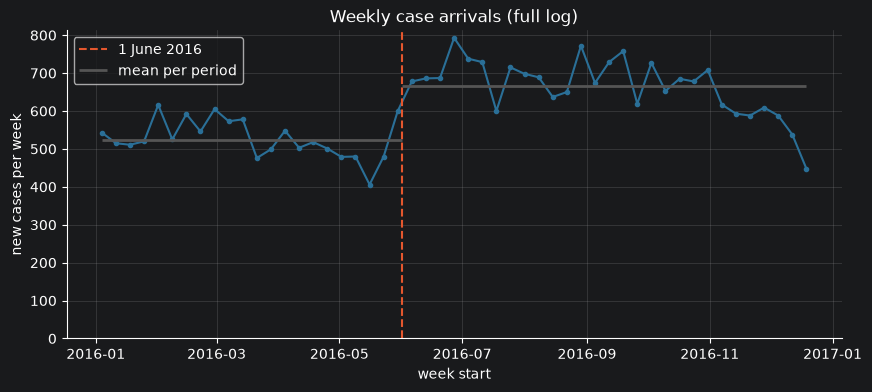

In [3]:
weekly = cases.groupby("start_week").size().rename("arrivals")
weekly = du.trim_partial_weeks(weekly)
week_end = weekly.index + pd.Timedelta(days=7)
split_naive = SPLIT_DATE.tz_localize(None)
straddles = (weekly.index < split_naive) & (week_end > split_naive)
weekly_test = weekly[~straddles]
w_before = weekly_test[weekly_test.index < split_naive]
w_after = weekly_test[weekly_test.index > split_naive]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.index, weekly.values, marker="o", ms=3, color=du.COLORS["complete"])
ax.axvline(split_naive, color=du.COLORS["after"], ls="--", label="1 June 2016")
ax.hlines(w_before.mean(), w_before.index[0], split_naive, color=du.COLORS["neutral"], lw=2)
ax.hlines(w_after.mean(), split_naive, w_after.index[-1], color=du.COLORS["neutral"], lw=2, label="mean per period")
ax.set_ylabel("new cases per week"); ax.set_xlabel("week start"); ax.set_ylim(bottom=0); ax.legend()
ax.set_title("Weekly case arrivals (full log)")
plt.show()

In [4]:
mean_b, mean_a = w_before.mean(), w_after.mean()
pd.Series({
    "weeks before": len(w_before), "weeks after": len(w_after),
    "mean arrivals/week before": mean_b, "mean arrivals/week after": mean_a,
    "change of mean [%]": 100 * du.rel_change(mean_b, mean_a),
}).to_frame("H1a arrivals")


,H1a arrivals
weeks before,21.000000
weeks after,29.000000
mean arrivals/week before,524.476190
mean arrivals/week after,664.965517
change of mean [%],26.786598


## 2. Case duration drift (complete cases)

In [5]:
cases_c["period"] = np.where(cases_c["start"] < SPLIT_DATE, "before", "after")
d_before = cases_c.loc[cases_c["period"] == "before", "duration_days"]
d_after = cases_c.loc[cases_c["period"] == "after", "duration_days"]

med_b, med_a = d_before.median(), d_after.median()
pd.DataFrame({
    "cases": [len(d_before), len(d_after)],
    "median [days]": [med_b, med_a],
    "mean [days]": [d_before.mean(), d_after.mean()],
}, index=["before", "after"]).round(1).assign(**{
    "change of median [%]": [None, round(100 * du.rel_change(med_b, med_a), 1)],
})


,cases,median [days],mean [days],change of median [%]
before,11305,17.7,21.4,NaN
after,20105,19.9,22.1,12.5


## 3. Concept drift check

In [6]:
events_cf = collapse_workitems(events_c, drop_withdrawn=True)
cases_cf = build_cases(events_cf)
cases_cf["period"] = np.where(cases_cf["start"] < SPLIT_DATE, "before", "after")
var_b = cases_cf.loc[cases_cf["period"] == "before", "variant"]
var_a = cases_cf.loc[cases_cf["period"] == "after", "variant"]

In [7]:
new_share = du.new_transition_share(var_b, var_a)
print(f"cases after the split with a new transition: {new_share:.1%}")
mix = du.verdict_mix(var_b, var_a)
mix[mix.max(axis=1) >= 0.1].round(1)

cases after the split with a new transition: 0.6%


,before [%],after [%]
variant,,
A_Pending,54.4,55.1
A_Cancelled,33.9,32.8
A_Denied,11.7,12.1


In [8]:
vt = du.variant_table(var_b, var_a, N_TOP_VARIANTS)
top_total = vt[["share_before", "share_after", "diff"]].sum().rename(f"Top {N_TOP_VARIANTS} total")
pd.concat([vt.drop(columns="variant"), top_total.to_frame().T]).round(4)

,share_before,share_after,diff
V1,0.1169,0.1191,0.0021
V2,0.0641,0.0390,-0.0251
V3,0.0563,0.0382,-0.0181
V4,0.0401,0.0450,0.0049
V5,0.0438,0.0355,-0.0083
V6,0.0289,0.0312,0.0023
V7,0.0208,0.0340,0.0132
V8,0.0321,0.0221,-0.0100
V9,0.0311,0.0198,-0.0113
V10,0.0222,0.0223,0.0001


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(vt))
ax.bar(x - 0.2, 100 * vt["share_before"], width=0.4, color=du.COLORS["before"], label="before")
ax.bar(x + 0.2, 100 * vt["share_after"], width=0.4, color=du.COLORS["after"], label="after")
ax.set_xticks(x); ax.set_xticklabels(vt.index); ax.set_ylabel("share of cases [%]"); ax.legend()
ax.set_title(f"Top {N_TOP_VARIANTS} variants: share before vs after")
plt.show()

## 4. New applications and duration

In [ ]:
from scipy import stats
wk = pd.DataFrame({
    "arrivals": weekly,
    "median_duration_days": cases_c.groupby("start_week")["duration_days"].median().reindex(weekly.index),
}).dropna()
rho, p_rho = stats.spearmanr(wk["arrivals"], wk["median_duration_days"])
print(f"n = {len(wk)} weeks, Spearman rho = {rho:.2f}, p = {du.fmt_p(p_rho)}")

after = wk.index > split_naive
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(wk.loc[~after, "arrivals"], wk.loc[~after, "median_duration_days"], color=du.COLORS["before"], label="before SPLIT_DATE")
ax.scatter(wk.loc[after, "arrivals"], wk.loc[after, "median_duration_days"], color=du.COLORS["after"], label="after SPLIT_DATE")
ax.set_xlabel("new cases per week"); ax.set_ylabel("median duration [days]"); ax.set_ylim(bottom=0)
ax.set_title(f"Arrivals vs median duration per week (Spearman rho = {rho:.2f})"); ax.legend()
plt.show()
